# Banking Conversion AI — Actividad 6

**Notebook de evaluación y validación estadística**, ejecutable y reproducible sobre los artefactos reales de `python -m fuentes.train`. Sigue la secuencia Markdown + código.

**Naturaleza de la evidencia:** las predicciones proceden de los modelos previamente entrenados en GitHub Actions; este cuaderno ejecuta y verifica las métricas sin repetir entrenamiento. La simulación A/B es retrospectiva y **no estima causalidad**. Fuente: UCI Bank Marketing (45,211 filas), DOI 10.24432/C5K306.

## Bloque 1. Entorno y acceso reproducible

Las dependencias están fijadas en `requirements.txt`. Se usa el directorio raíz del repositorio incluso si Jupyter ejecuta este notebook desde `notebooks/`.

In [1]:
import json, platform, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import display, Image
cwd=Path.cwd().resolve()
ROOT=next((q for q in (cwd,*cwd.parents) if (q/"resultados/resumen.json").exists()),None)
assert ROOT is not None, "Primero ejecutar python -m fuentes.train desde la raíz"
sys.path.insert(0,str(ROOT))
R=ROOT/"resultados"
meta=json.loads((R/"resumen.json").read_text(encoding="utf-8"))
print("Python:",sys.version.split()[0],"; Entorno auditor:",platform.platform())
print("Dataset:",meta["filas"],"positivos:",meta["positivos"])
print("Particiones:",meta["splits"])

Python: 3.11.17 ; Entorno auditor: Linux-7.0.0-1017-azure-x86_64-with-glibc2.43
Dataset: 45211 positivos: 5289
Particiones: {'train': 27126, 'validation': 9042, 'test': 9043}


## Bloque 2. Calidad del dataset y fuga de información

Se valida que el CSV original coincide con la documentación: 45,211 registros, 17 columnas y 5,289 `yes`. El pipeline excluye duración y variables ambiguas de la campaña actual.

In [2]:
from fuentes.datos import FEATURES,EXCLUDED
d=pd.read_csv(ROOT/"datos/bank-full.csv",sep=";",keep_default_na=False)
splits=pd.read_csv(ROOT/"datos/splits.csv")
assert d.shape==(45211,17)
assert (d.y=="yes").sum()==5289
assert len(splits)==len(d) and splits.indice_original.is_unique
assert not set(FEATURES).intersection(set(EXCLUDED))
assert "duration" not in FEATURES
display(pd.DataFrame({"clase":d.y.value_counts().index,"registros":d.y.value_counts().values}))
print("Predictoras:",FEATURES)
print("Exclusiones:",EXCLUDED)

,clase,registros
0,no,39922
1,yes,5289


Predictoras: ['age', 'balance', 'pdays', 'previous', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome']
Exclusiones: ['duration', 'contact', 'day', 'month', 'campaign']


## Bloque 3. Matriz de confusión y métricas

Los umbrales se optimizaron solo en validación; en test se reconstruyen TN, FP, FN y TP a partir de las predicciones publicadas, sin recalcular los umbrales.

,Modelo,validation_threshold,test_precision,test_recall,test_f1,test_roc_auc,test_average_precision
0,LogisticRegression,0.11,0.2059,0.6474,0.3124,0.7204,0.3470
1,RandomForest,0.12,0.2561,0.5756,0.3545,0.7392,0.3838


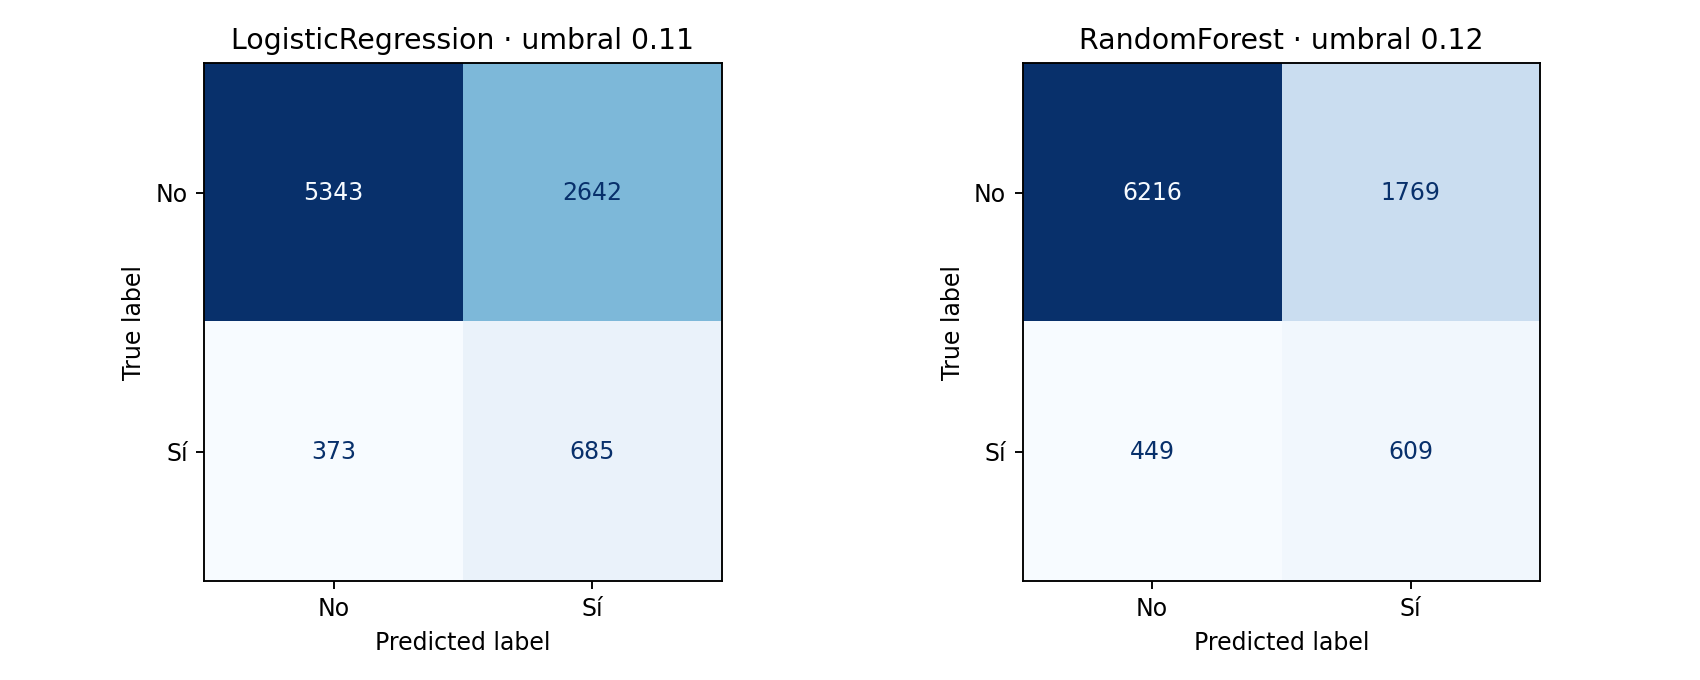

Test auditado: 9,043 registros, sin discrepancias.


In [3]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, average_precision_score
comparison=pd.read_csv(R/"comparacion_modelos.csv")
pred=pd.read_csv(R/"predicciones_test.csv")
selection=json.loads((R/"seleccion_congelada.json").read_text(encoding="utf-8"))
assert selection["test_no_usado_para_seleccion"]
for _,v in comparison.iterrows():
    n=v["Modelo"]
    p=pred[f"{n}_prob"].to_numpy()
    y=pred.y.to_numpy()
    yhat=pred[f"{n}_pred"].to_numpy()
    th=selection["umbrales_por_modelo"][n]
    assert np.array_equal((p>=th).astype(int),yhat)
    tn,fp,fn,tp=confusion_matrix(y,yhat).ravel()
    assert (tn,fp,fn,tp)==tuple(int(v["test_"+k]) for k in ("tn","fp","fn","tp"))
    assert np.isclose(f1_score(y,yhat),v.test_f1)
    assert np.isclose(roc_auc_score(y,p),v.test_roc_auc)
display(comparison[["Modelo","validation_threshold","test_precision","test_recall","test_f1","test_roc_auc","test_average_precision"]].round(4))
display(Image(filename=str(R/"figuras/03_matrices_confusion.png")))
print("Test auditado: 9,043 registros, sin discrepancias.")

## Bloque 4. ROC-AUC, Precision-Recall y baseline

La curva ROC describe capacidad de discriminación y Average Precision refleja de forma más sensible el problema de respuestas minoritarias. El baseline prior se reporta con recall=0 a umbral 0.50.

,Baseline accuracy,Baseline recall,Baseline F1
0,0.883,0.0,0.0


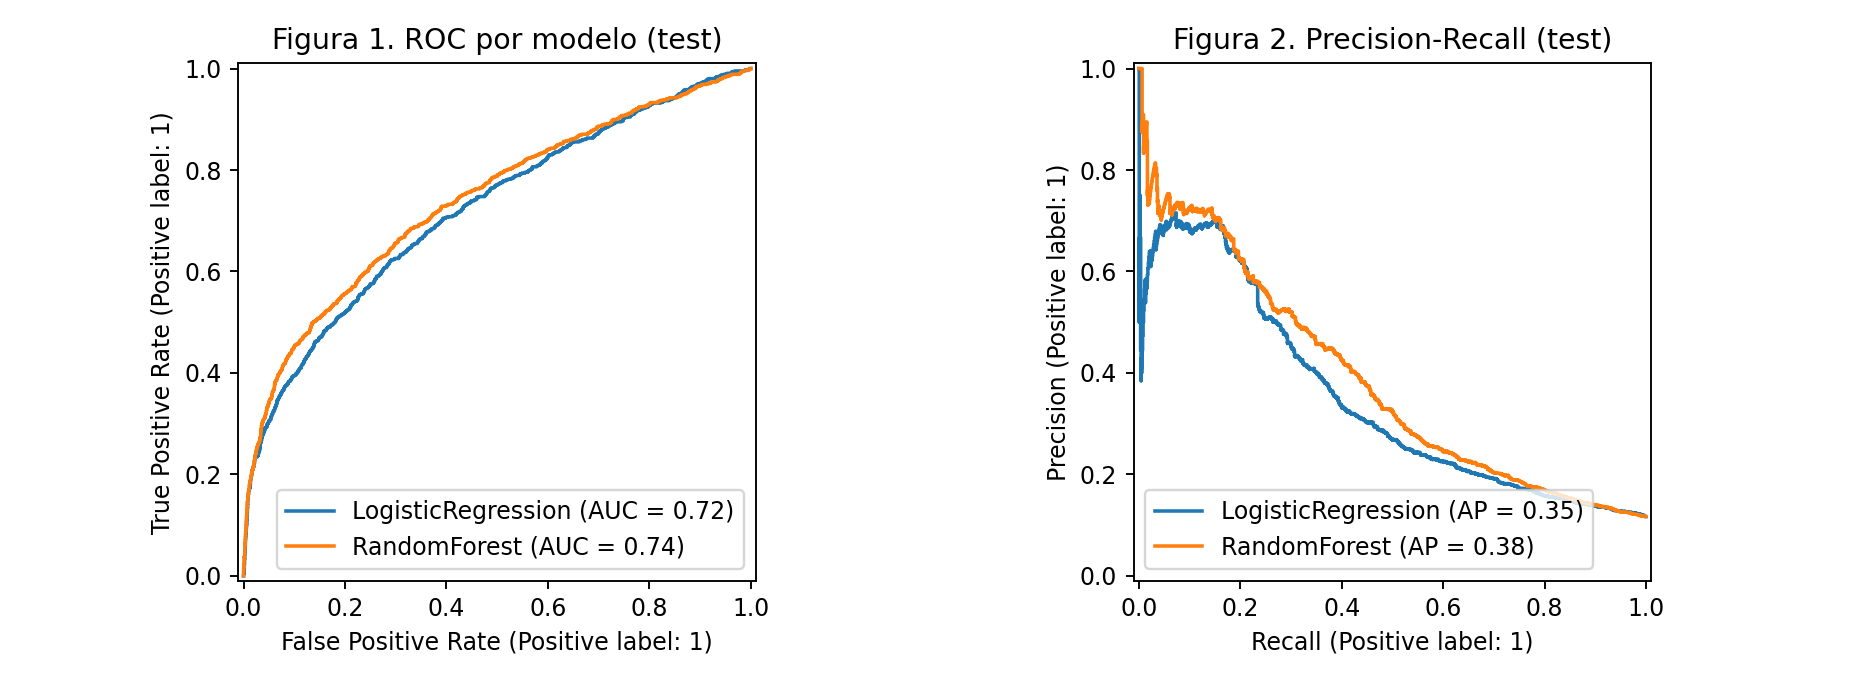

Fijar umbrales por test sería filtración; NO se realiza.


In [4]:
baseline=json.loads((R/"baseline_dummy.json").read_text(encoding="utf-8"))
assert baseline["recall"]==0 and baseline["tp"]==0
display(pd.DataFrame([{"Baseline accuracy":baseline["accuracy"],"Baseline recall":baseline["recall"],"Baseline F1":baseline["f1"]}]).round(4))
display(Image(filename=str(R/"figuras/01_02_curvas_roc_pr.png")))
print("Fijar umbrales por test sería filtración; NO se realiza.")

## Bloque 5. Validación cruzada y ajuste de umbral

La búsqueda de hiperparámetros se ejecutó sobre entrenamiento usando cinco folds; los umbrales se eligieron separadamente en validación con restricción de precisión mayor o igual a 0.20.

,Modelo,cv_average_precision,validation_f2,validation_precision,validation_recall,validation_threshold,best_params_json
0,LogisticRegression,0.3435,0.4640,0.2134,0.6569,0.11,"{""model__C"": 0.1, ""model__class_weight"": null}"
1,RandomForest,0.3670,0.4809,0.2733,0.5936,0.12,"{""model__max_depth"": 10, ""model__min_samples_l..."


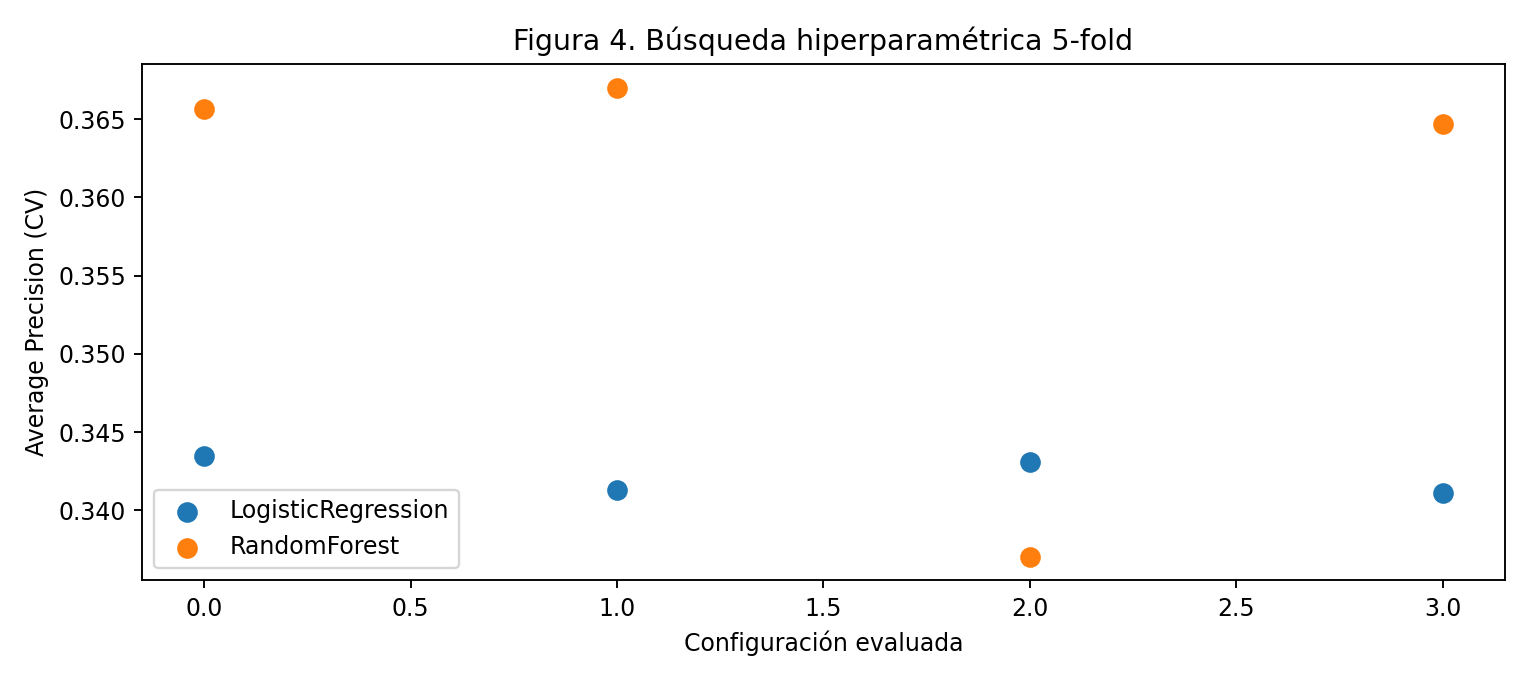

CV configura modelos; validación ajusta umbrales; test reporta desempeño final.


In [5]:
cv=pd.read_csv(R/"gridsearch_cv.csv")
assert set(cv["modelo"])=={"LogisticRegression","RandomForest"}
assert len(cv)==8
assert all(comparison["precision_constraint_feasible"])
display(comparison[["Modelo","cv_average_precision","validation_f2","validation_precision","validation_recall","validation_threshold","best_params_json"]].round(4))
display(Image(filename=str(R/"figuras/04_cv.png")))
print("CV configura modelos; validación ajusta umbrales; test reporta desempeño final.")

## Bloque 6. Significancia estadística y bootstrap

McNemar compara discordancias de error sobre las mismas observaciones. El bootstrap pareado estima la incertidumbre de la diferencia F1 entre Random Forest y regresión logística.

In [6]:
bootstrap=pd.read_csv(R/"bootstrap_pareado.csv")
mcnemar=json.loads((R/"mcnemar.json").read_text(encoding="utf-8"))
assert bootstrap.loc[0,"repeticiones"]==1000
assert mcnemar["discordantes"]==(mcnemar["a_correcto_b_error"]+mcnemar["a_error_b_correcto"])
display(bootstrap.round(6))
display(pd.DataFrame([mcnemar]))
print("La significancia predictiva no equivale a impacto causal bancario.")

,comparacion,delta_f1,ic95_inferior,ic95_superior,repeticiones,pareado
0,RandomForest - LogisticRegression,0.042053,0.031254,0.052591,1000,True


,a_correcto_b_error,a_error_b_correcto,discordantes,p_exacto_bilateral
0,216,1013,1229,1.120441e-123


La significancia predictiva no equivale a impacto causal bancario.


## Bloque 7. Simulación A/B offline

Grupo A usa selección aleatoria, grupo B prioriza scores de Random Forest, ambos con 20% de capacidad de contacto en subconjuntos disjuntos. Se observan etiquetas históricas de una campaña ya realizada, **no respuestas a la intervención hipotética**.

,Estrategia,Contactados,Conversiones históricas,Tasa
0,A: aleatoria,904,88,0.0973
1,B: ranking RF,904,270,0.2987


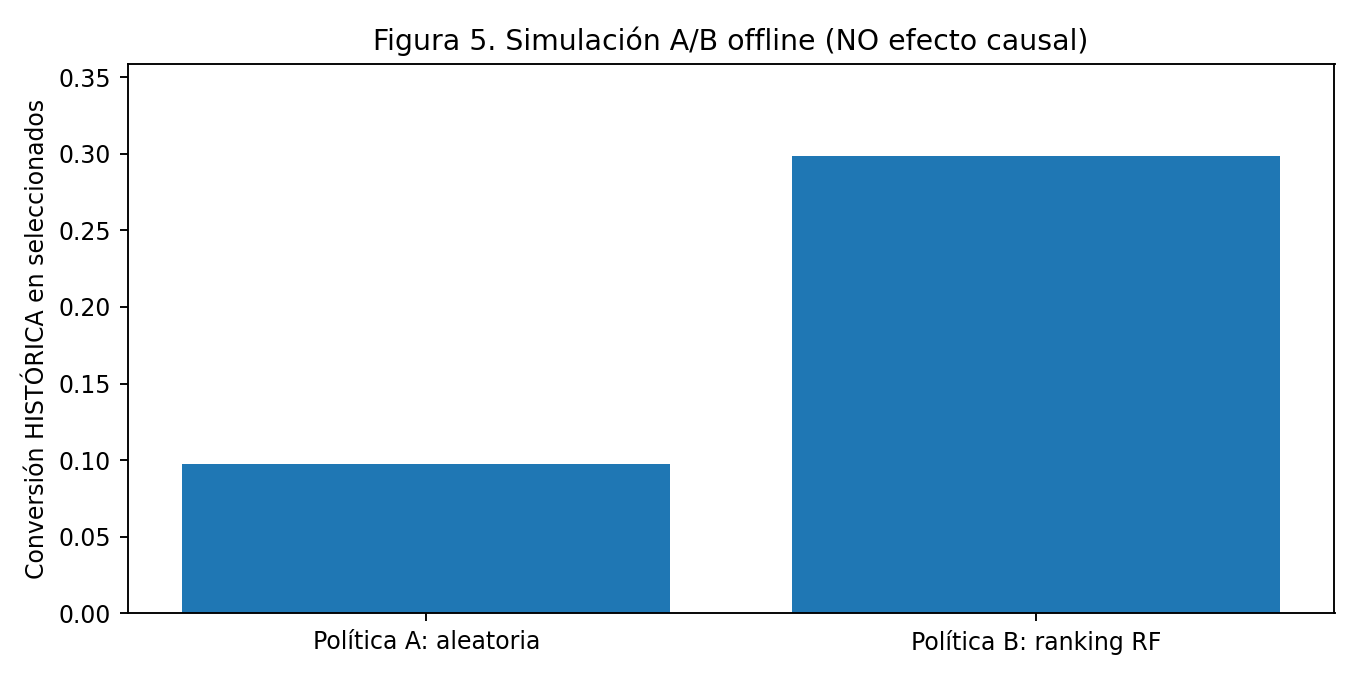

NO experimento real; observaciones históricas, selección condicionada por score y ausencia de contrafactual sin contacto. No estimar uplift causal.


In [7]:
ab=json.loads((R/"simulacion_ab.json").read_text(encoding="utf-8"))
assert ab["tipo"]=="simulacion_AB_offline_no_causal"
assert ab["contactados_A"]==ab["contactados_B"]==904
assert 0<=ab["tasa_A"]<=1 and 0<=ab["tasa_B"]<=1
display(pd.DataFrame([{"Estrategia":"A: aleatoria","Contactados":ab["contactados_A"],"Conversiones históricas":ab["conversiones_historicas_A"],"Tasa":ab["tasa_A"]},
                      {"Estrategia":"B: ranking RF","Contactados":ab["contactados_B"],"Conversiones históricas":ab["conversiones_historicas_B"],"Tasa":ab["tasa_B"]}]).round(4))
display(Image(filename=str(R/"figuras/05_ab_offline.png")))
print(ab["advertencia"])

## Bloque 8. Conclusión contextual

El algoritmo ganador fue seleccionado previamente con F2 de validación; el resultado de prueba no se usó para elegir ni refinar hiperparámetros. La priorización podría dirigir recursos comerciales hacia clientes históricamente más propensos a contratar, pero la mejora causal, seguridad, equidad y generalización temporal requieren ensayos reales.

In [8]:
best=selection["modelo_seleccionado_en_validacion"]
winner=comparison.set_index("Modelo").loc[best]
print("Modelo preseleccionado:",best,"umbral:",selection["umbral"])
print("F1 test:",round(float(winner.test_f1),4),"ROC-AUC:",round(float(winner.test_roc_auc),4))
print("Recomendación: piloto prospectivo A/B controlado, supervisión humana y auditoría de fairness.")
print("EVIDENCIAS AUDITADAS. No se entrenaron modelos nuevos desde este notebook.")

Modelo preseleccionado: RandomForest umbral: 0.12
F1 test: 0.3545 ROC-AUC: 0.7392
Recomendación: piloto prospectivo A/B controlado, supervisión humana y auditoría de fairness.
EVIDENCIAS AUDITADAS. No se entrenaron modelos nuevos desde este notebook.
